# Homework 6

**Name:** Karan Verma  
**GitHub Username:** kv304  
**USC ID:** 5639810577


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    confusion_matrix,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 5)

RANDOM_STATE = 552
DATA_DIR = Path("data")


## 1. Tree-Based Methods

### 1(a) Read and prepare the APS Failure data

The CSV files contain introductory lines before the header, so the loader first locates the line beginning with `class,`. Missing values are encoded as `na` in the source files.


In [2]:
def load_aps_file(filename):
    file_path = DATA_DIR / filename
    with file_path.open() as stream:
        header_row = next(
            row_number
            for row_number, line in enumerate(stream)
            if line.startswith("class,")
        )
    return pd.read_csv(file_path, skiprows=header_row, na_values="na")


training_frame = load_aps_file("aps_failure_training_set.csv")
test_frame = load_aps_file("aps_failure_test_set.csv")

X_train = training_frame.drop(columns="class")
X_test = test_frame.drop(columns="class")
y_train = training_frame["class"].map({"neg": 0, "pos": 1})
y_test = test_frame["class"].map({"neg": 0, "pos": 1})

assert X_train.shape == (60000, 170)
assert X_test.shape == (16000, 170)
assert X_train.columns.equals(X_test.columns)
assert not y_train.isna().any() and not y_test.isna().any()

print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)


Training predictors: (60000, 170)
Test predictors: (16000, 170)


The dimensions match the data description: 60,000 training observations, 16,000 test observations, and 170 numeric predictors in both files.

### 1(b) Data preparation

#### 1(b)(i) Missing values

Common choices include deletion, mean or median imputation, nearest-neighbor imputation, and iterative model-based imputation. Deleting rows would discard too much information here. I use median imputation because it is simple and resistant to extreme sensor readings. The exploratory copy below is fitted only on the training set. During model fitting, imputation remains inside each pipeline so each validation fold learns its medians without seeing the held-out fold.


In [3]:
eda_imputer = SimpleImputer(strategy="median", keep_empty_features=True)
imputed_training = pd.DataFrame(
    eda_imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)

print("Missing training entries:", int(X_train.isna().sum().sum()))
print(
    "Missing entries after imputation:",
    int(imputed_training.isna().sum().sum()),
)
assert np.isfinite(imputed_training.to_numpy()).all()


Missing training entries: 850015
Missing entries after imputation: 0


There are 850,015 missing training entries. Median imputation fills all of them without removing observations.

#### 1(b)(ii) Coefficient of variation

The coefficient of variation is calculated for all 170 predictors using the sample standard deviation, `CV = s / m`. Only the 13 largest finite values are displayed because `floor(sqrt(170)) = 13` and those variables are used in the next visualization.


In [4]:
feature_cv = (
    imputed_training.std(ddof=1)
    / imputed_training.mean().replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan)

high_cv_features = feature_cv.dropna().nlargest(13).index.tolist()

print("CV values calculated:", len(feature_cv))
display(feature_cv.loc[high_cv_features].rename("CV").to_frame())


CV values calculated: 170


,CV
cf_000,244.88752
co_000,244.50739
ad_000,244.32282
cs_009,237.93055
dh_000,123.21610
dj_000,117.49423
ag_000,92.91776
as_000,87.33250
ay_009,84.73373
ak_000,80.42498


The largest CV values belong to sparse predictors whose means are close to zero. A high CV indicates large relative dispersion; it does not by itself imply predictive importance.

#### 1(b)(iii) Correlation matrix


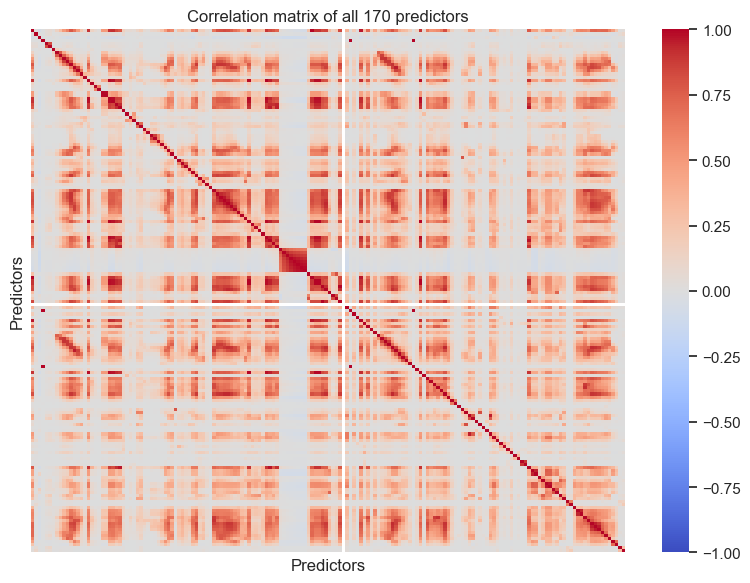

In [5]:
feature_correlations = imputed_training.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    feature_correlations,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,
    yticklabels=False,
)
plt.title("Correlation matrix of all 170 predictors")
plt.xlabel("Predictors")
plt.ylabel("Predictors")
plt.tight_layout()
plt.show()


The scatterplots use a balanced sample of 500 observations from each class so the rare positive class remains visible. Each feature is shown in its own panel with a small vertical jitter and a `log1p` transformation for the strongly right-skewed sensor values. The boxplots use the same transformed scale but retain all training observations. These choices are only for visualization; model fitting still uses all 60,000 rows on the original scale.


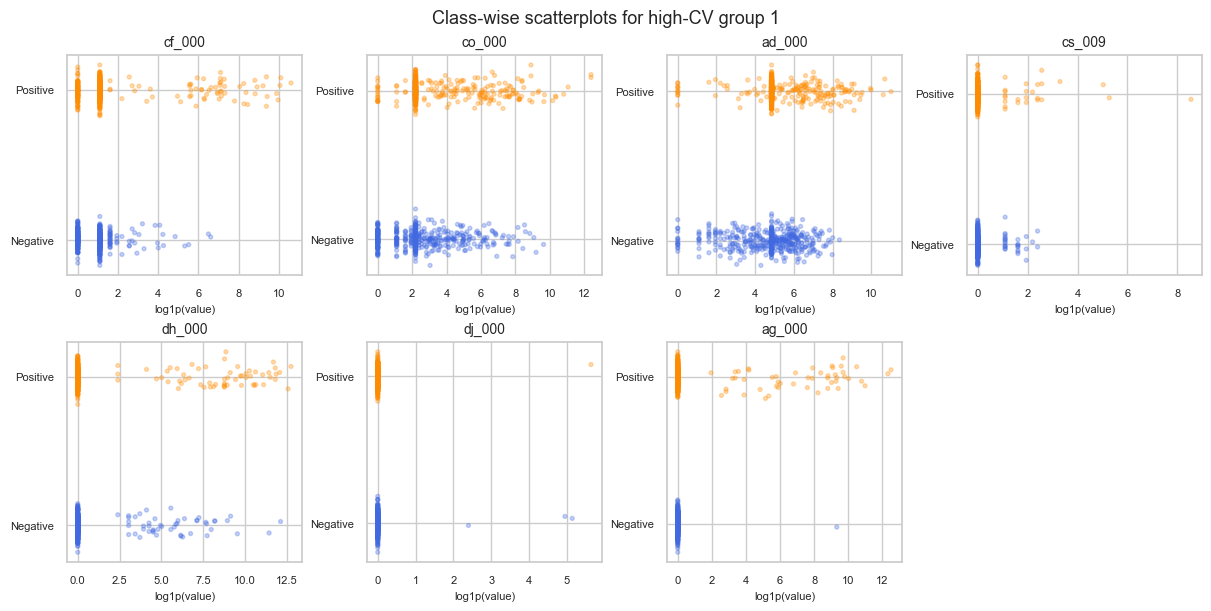

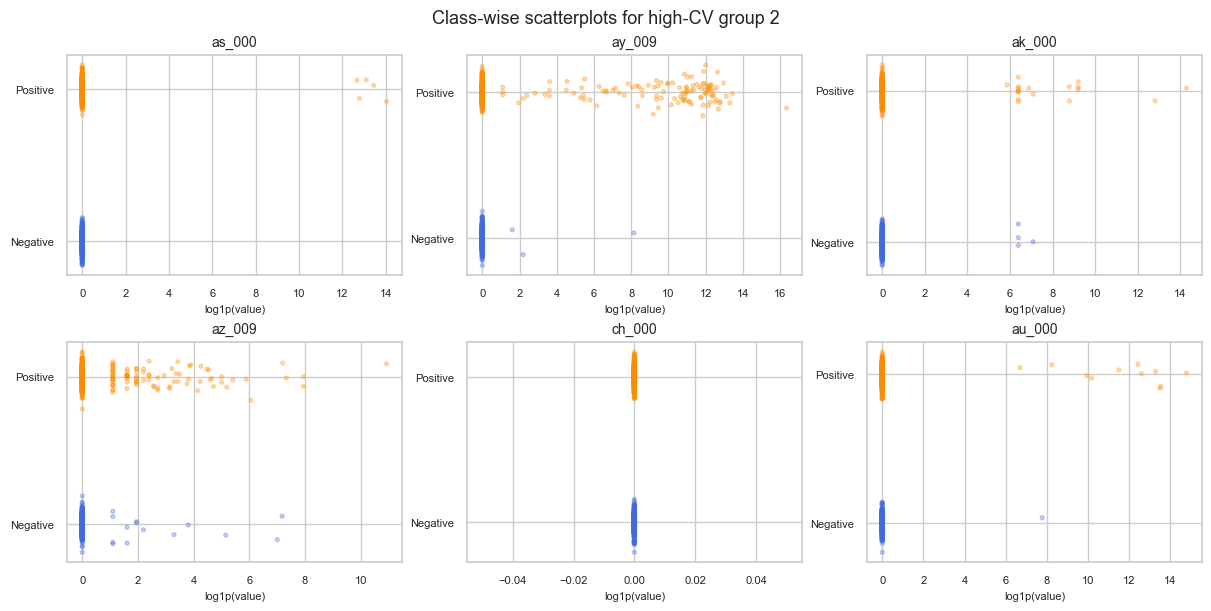

In [6]:
visualization_data = imputed_training[high_cv_features].copy()
visualization_data["Class"] = y_train.map(
    {0: "Negative", 1: "Positive"}
)

# Use a balanced sample only for visualization so the rare positive class
# remains visible. All models still use the complete training set.
negative_sample = visualization_data[
    visualization_data["Class"] == "Negative"
].sample(500, random_state=RANDOM_STATE)
positive_sample = visualization_data[
    visualization_data["Class"] == "Positive"
].sample(500, random_state=RANDOM_STATE)
plot_sample = pd.concat([negative_sample, positive_sample])

feature_groups = [high_cv_features[:7], high_cv_features[7:]]
rng = np.random.default_rng(RANDOM_STATE)
class_position = plot_sample["Class"].map(
    {"Negative": 0, "Positive": 1}
).to_numpy()

for group_number, feature_group in enumerate(feature_groups, start=1):
    columns = 4 if len(feature_group) > 6 else 3
    figure, axes = plt.subplots(
        2, columns, figsize=(12, 6), constrained_layout=True
    )

    for axis, feature in zip(axes.flat, feature_group):
        jitter = rng.normal(0, 0.055, len(plot_sample))
        point_colors = plot_sample["Class"].map(
            {"Negative": "royalblue", "Positive": "darkorange"}
        )
        axis.scatter(
            np.log1p(plot_sample[feature]),
            class_position + jitter,
            c=point_colors,
            s=8,
            alpha=0.3,
        )
        axis.set_title(feature, fontsize=10)
        axis.set_xlabel("log1p(value)", fontsize=8)
        axis.set_yticks([0, 1], ["Negative", "Positive"])
        axis.tick_params(labelsize=8)

    for axis in axes.flat[len(feature_group):]:
        axis.set_visible(False)

    figure.suptitle(
        f"Class-wise scatterplots for high-CV group {group_number}",
        fontsize=13,
    )
    plt.show()


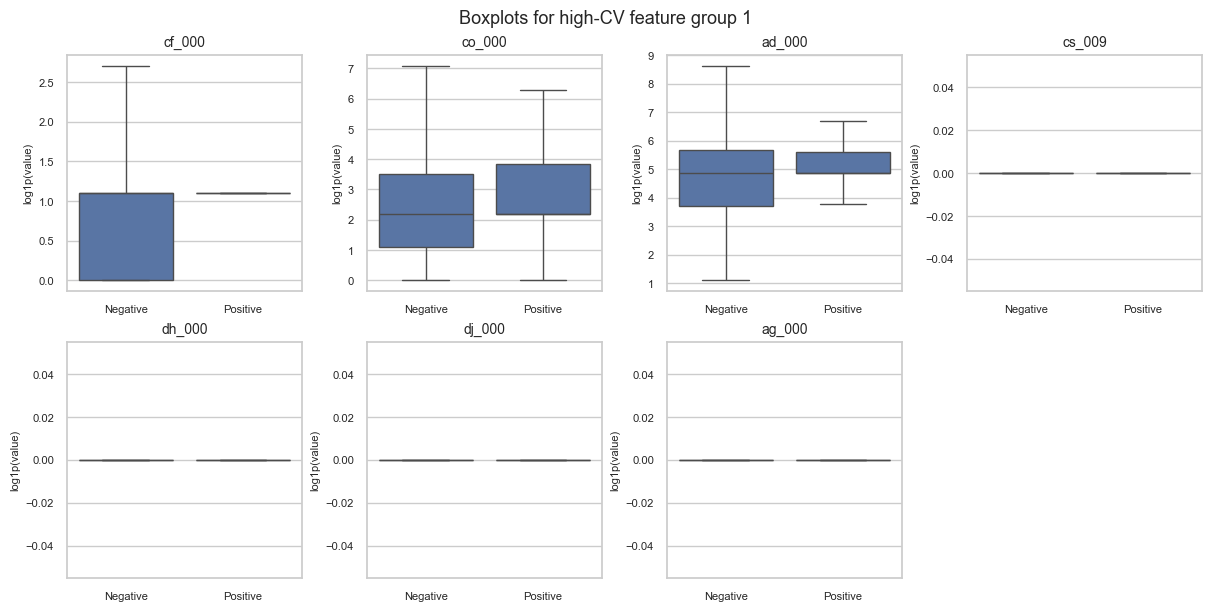

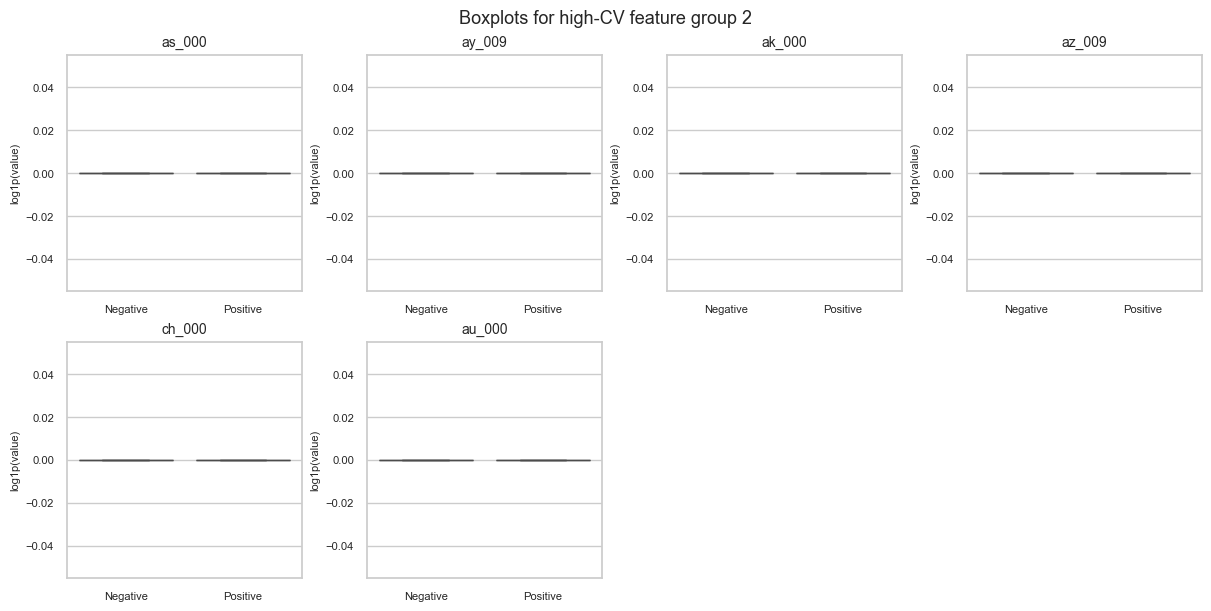

In [7]:
boxplot_data = visualization_data.copy()
boxplot_data[high_cv_features] = np.log1p(
    boxplot_data[high_cv_features]
)

for group_number, feature_group in enumerate(feature_groups, start=1):
    figure, axes = plt.subplots(
        2, 4, figsize=(12, 6), constrained_layout=True
    )

    for axis, feature in zip(axes.flat, feature_group):
        sns.boxplot(
            data=boxplot_data,
            x="Class",
            y=feature,
            showfliers=False,
            ax=axis,
        )
        axis.set_title(feature, fontsize=10)
        axis.set_xlabel("")
        axis.set_ylabel("log1p(value)", fontsize=8)
        axis.tick_params(labelsize=8)

    for axis in axes.flat[len(feature_group):]:
        axis.set_visible(False)

    figure.suptitle(
        f"Boxplots for high-CV feature group {group_number}",
        fontsize=13,
    )
    plt.show()


Most values are concentrated near zero and several predictors are strongly right-skewed. Some positive observations occupy wider ranges, but the classes still overlap substantially. The plots suggest possible relationships and outliers, not statistical significance: they do not quantify uncertainty or control for the other predictors.

#### 1(b)(v) Class imbalance


In [8]:
class_counts = y_train.value_counts().reindex([0, 1])
class_counts.index = ["Negative", "Positive"]

display(pd.DataFrame({
    "Count": class_counts,
    "Percentage": 100 * class_counts / len(y_train),
}).round(2))

print("Always-negative error:", round(y_train.mean(), 4))


,Count,Percentage
Negative,59000,98.33
Positive,1000,1.67


Always-negative error: 0.0167


Only 1,000 of the 60,000 training observations (1.67%) are positive, so the data are severely imbalanced. An always-negative classifier would already achieve 98.33% accuracy. For that reason, I report positive-class recall, false negatives, and ROC AUC in addition to total error.


In [9]:
evaluation_rows = []


def evaluate_classifier(model, model_name):
    split_results = []

    for split_name, predictors, labels in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test),
    ]:
        predictions = model.predict(predictors)
        probabilities = model.predict_proba(predictors)[:, 1]
        matrix = confusion_matrix(labels, predictions, labels=[0, 1])
        true_negative, false_positive, false_negative, true_positive = (
            matrix.ravel()
        )

        split_results.append(
            (split_name, labels, probabilities, matrix)
        )
        evaluation_rows.append({
            "Model": model_name,
            "Split": split_name,
            "Error": 1 - accuracy_score(labels, predictions),
            "AUC": roc_auc_score(labels, probabilities),
            "Recall": recall_score(
                labels, predictions, zero_division=0
            ),
            "FP": false_positive,
            "FN": false_negative,
        })

    # Use one spacious diagnostic figure for both matrices and the ROC curves.
    diagnostic_figure = plt.figure(figsize=(9, 8), constrained_layout=True)
    grid = diagnostic_figure.add_gridspec(2, 2, height_ratios=[1, 1.35])
    matrix_axes = [
        diagnostic_figure.add_subplot(grid[0, 0]),
        diagnostic_figure.add_subplot(grid[0, 1]),
    ]
    roc_axis = diagnostic_figure.add_subplot(grid[1, :])

    for axis, (split_name, labels, probabilities, matrix) in zip(
        matrix_axes, split_results
    ):
        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            square=True,
            ax=axis,
        )
        axis.set_title(f"{split_name} confusion matrix")
        axis.set_xlabel("Predicted class")
        axis.set_ylabel("Actual class")
        axis.set_xticklabels(["Negative", "Positive"])
        axis.set_yticklabels(
            ["Negative", "Positive"], rotation=0
        )
        RocCurveDisplay.from_predictions(
            labels,
            probabilities,
            name=split_name,
            ax=roc_axis,
        )
    roc_axis.plot([0, 1], [0, 1], "--", color="gray")
    roc_axis.set_title("ROC curves")
    roc_axis.legend(loc="lower right")
    diagnostic_figure.suptitle(model_name, fontsize=14)
    plt.show()


### 1(c) Ordinary random forest

This forest uses every predictor and does not compensate for class imbalance.


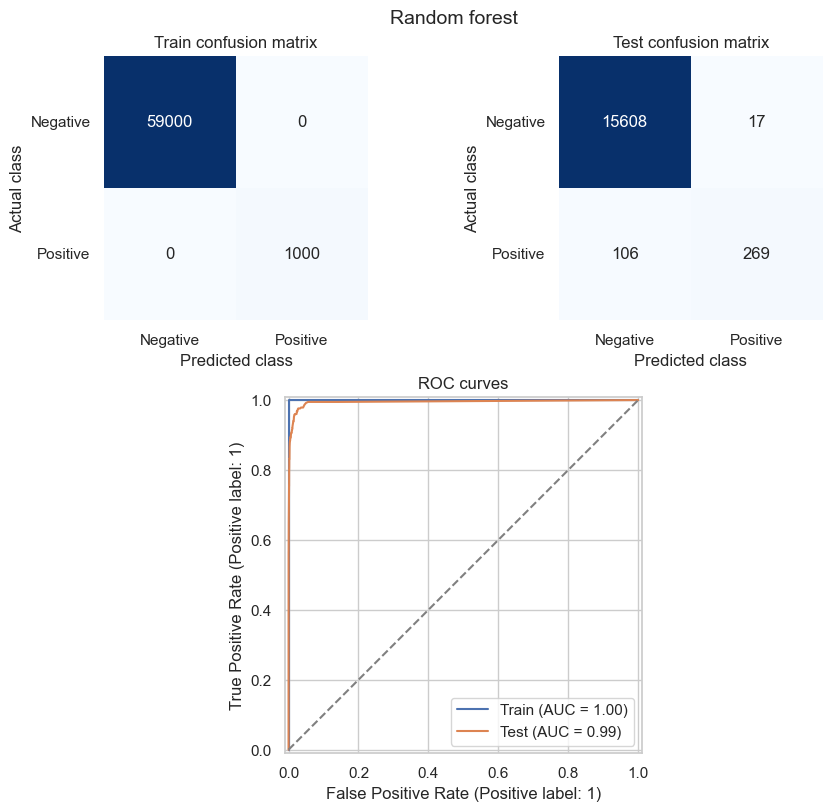

OOB error: 0.0057


In [10]:
plain_forest = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median", keep_empty_features=True),
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=300,
            oob_score=True,
            random_state=RANDOM_STATE,
            n_jobs=4,
        ),
    ),
])

plain_forest.fit(X_train, y_train)
evaluate_classifier(plain_forest, "Random forest")

plain_oob_error = 1 - plain_forest.named_steps["model"].oob_score_
print("OOB error:", round(plain_oob_error, 4))


The ordinary forest perfectly fits the training data. On the test set it produces 17 false positives and 106 false negatives, giving error 0.0077, recall 0.7173, and AUC 0.9944. Its OOB error is 0.0057, which is close to, but slightly lower than, the test error.

### 1(d) Class-weighted random forest

Random forests can address imbalance through class-weighted split criteria or balanced bootstrap samples. Here `class_weight="balanced"` weights each class inversely to its observed frequency while leaving the remaining forest settings unchanged.


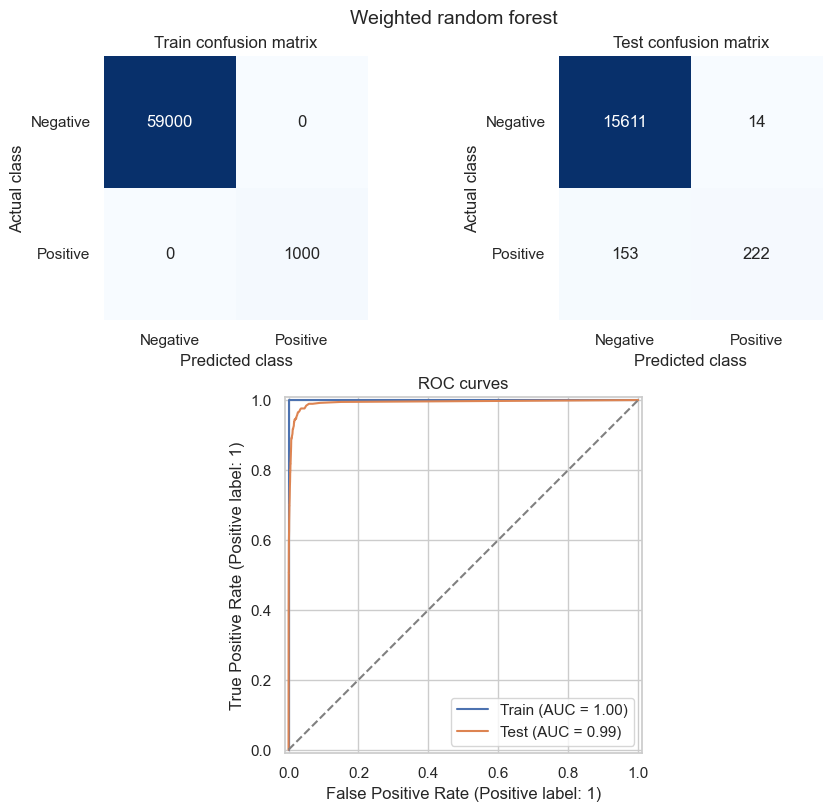

OOB error: 0.0075


In [11]:
weighted_forest = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median", keep_empty_features=True),
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            oob_score=True,
            random_state=RANDOM_STATE,
            n_jobs=4,
        ),
    ),
])

weighted_forest.fit(X_train, y_train)
evaluate_classifier(weighted_forest, "Weighted random forest")

weighted_oob_error = (
    1 - weighted_forest.named_steps["model"].oob_score_
)
print("OOB error:", round(weighted_oob_error, 4))


Weighting does not improve this particular forest. Relative to the ordinary forest, test false negatives increase from 106 to 153 and recall falls from 0.7173 to 0.5920. False positives decrease slightly from 17 to 14, but test error rises from 0.0077 to 0.0104 and AUC falls from 0.9944 to 0.9929. The weighted OOB error, 0.0075, is again somewhat lower than the corresponding test error, 0.0104. Class weighting changes the learning objective, but it does not guarantee better minority-class predictions for every fitted model.

### 1(e) XGBoost without imbalance compensation

Five-fold stratified cross-validation selects the L1 regularization parameter `reg_alpha`. Accuracy is used so that `1 - best_score_` is the requested cross-validation error; recall and AUC are also reported because accuracy alone can hide minority-class errors.


Selected alpha: 0.1
Model-selection CV error: 0.006


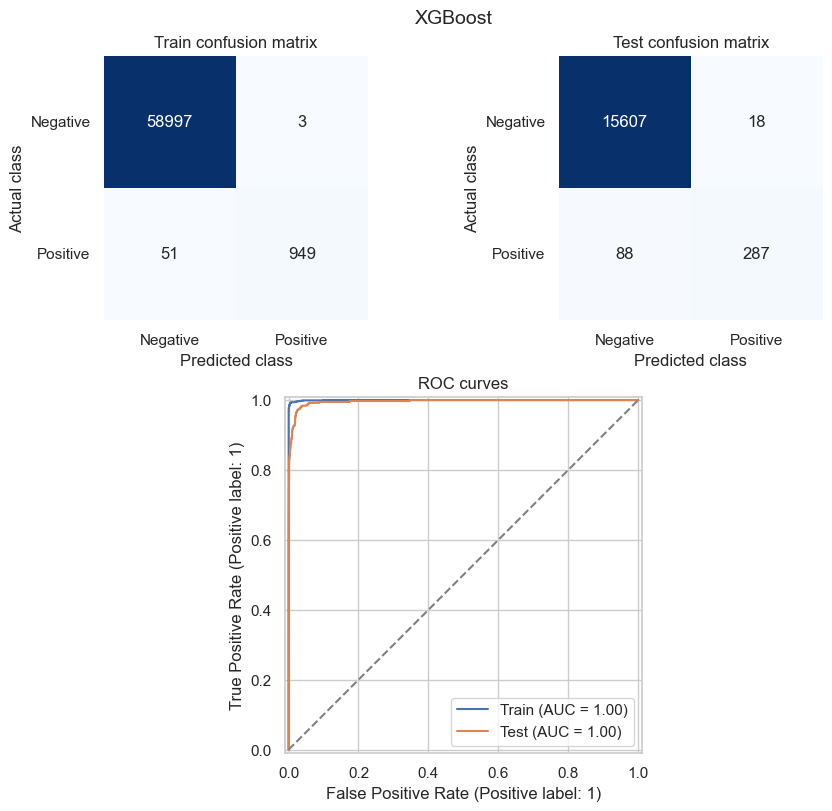

In [12]:
tuning_folds = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

xgb_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median", keep_empty_features=True),
    ),
    ("scaler", StandardScaler()),
    (
        "model",
        XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=4,
        ),
    ),
])

xgb_search = GridSearchCV(
    xgb_pipeline,
    {"model__reg_alpha": [0, 0.1, 1, 10]},
    scoring="accuracy",
    cv=tuning_folds,
    n_jobs=1,
)
xgb_search.fit(X_train, y_train)

print("Selected alpha:", xgb_search.best_params_["model__reg_alpha"])
print(
    "Model-selection CV error:",
    round(1 - xgb_search.best_score_, 4),
)
evaluate_classifier(xgb_search.best_estimator_, "XGBoost")


Cross-validation selects `alpha = 0.1` and estimates an error of 0.0060. The test error is 0.0066, so the cross-validation estimate is reasonably close. Test recall is 0.7653, test AUC is 0.9957, and the test confusion matrix contains 18 false positives and 88 false negatives. In standard XGBoost, `reg_alpha` applies an L1 penalty to leaf weights; it does not literally fit a separate logistic regression at every node.

### 1(f) XGBoost with SMOTE

The imbalanced-learn pipeline performs imputation, scaling, SMOTE, and model fitting inside each cross-validation fold. Consequently, synthetic observations are created only from that fold's training portion and cannot leak into its validation portion.


Selected alpha: 0.1
Model-selection CV error: 0.0095


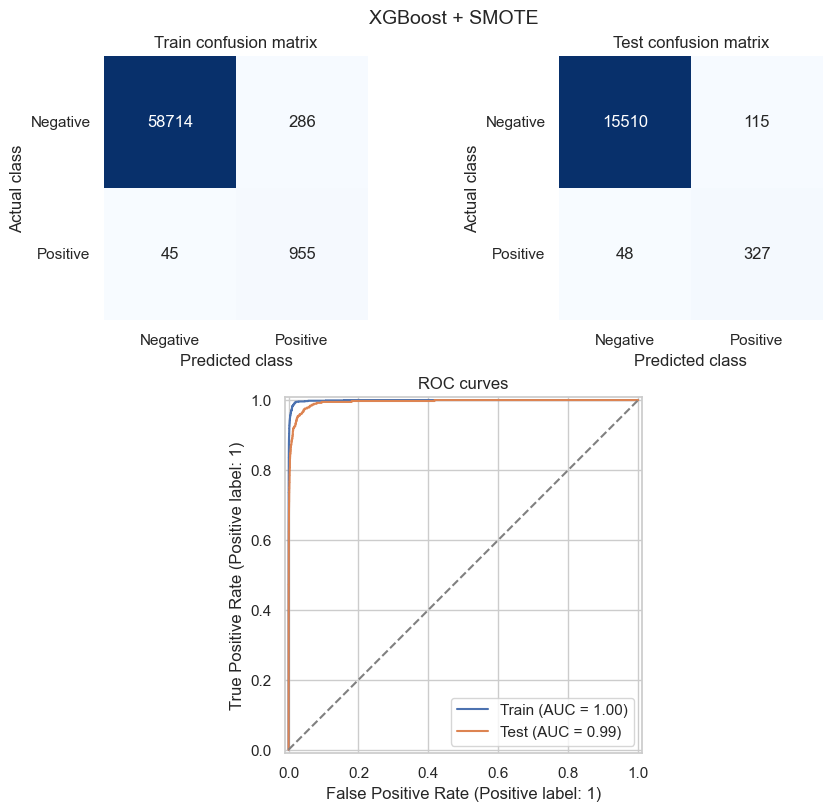

In [13]:
smote_xgb_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median", keep_empty_features=True),
    ),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    (
        "model",
        XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.1,
            tree_method="hist",
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=4,
        ),
    ),
])

smote_search = GridSearchCV(
    smote_xgb_pipeline,
    {"model__reg_alpha": [0, 0.1, 1, 10]},
    scoring="accuracy",
    cv=tuning_folds,
    n_jobs=1,
)
smote_search.fit(X_train, y_train)

print("Selected alpha:", smote_search.best_params_["model__reg_alpha"])
print(
    "Model-selection CV error:",
    round(1 - smote_search.best_score_, 4),
)
evaluate_classifier(smote_search.best_estimator_, "XGBoost + SMOTE")


In [14]:
model_summary = pd.DataFrame(evaluation_rows)
display(model_summary.round(4))


,Model,Split,Error,AUC,Recall,FP,FN
0,Random forest,Train,0.0000,1.0000,1.0000,0,0
1,Random forest,Test,0.0077,0.9944,0.7173,17,106
2,Weighted random forest,Train,0.0000,1.0000,1.0000,0,0
3,Weighted random forest,Test,0.0104,0.9929,0.5920,14,153
4,XGBoost,Train,0.0009,0.9997,0.9490,3,51
5,XGBoost,Test,0.0066,0.9957,0.7653,18,88
6,XGBoost + SMOTE,Train,0.0055,0.9989,0.9550,286,45
7,XGBoost + SMOTE,Test,0.0102,0.9943,0.8720,115,48


SMOTE reduces the test false negatives from 88 to 48 and raises positive-class recall from 0.7653 to 0.8720. The cost is that false positives increase from 18 to 115. This raises the test error from 0.0066 to 0.0102, while AUC drops slightly from 0.9957 to 0.9943. I would use the SMOTE model if missing an actual truck failure is much more costly than checking a false alarm. Otherwise, the regular XGBoost model has the lower overall error.

## 2. ISLR 6.6, Exercise 3

Here, `s` controls how restrictive the lasso constraint is. Starting from zero and increasing `s` allows the coefficients to move farther away from zero, so the model becomes more flexible.

- **(a) iv - steadily decrease.** The set of allowed coefficient values gets larger as `s` increases. Therefore, the best training RSS cannot become worse. It may level off after the least-squares solution becomes available.
- **(b) ii - decrease first and then increase.** A small increase in flexibility can improve test performance, but too much flexibility can cause overfitting. This gives the usual U-shaped test RSS.
- **(c) iii - steadily increase.** A more flexible fit changes more when the training sample changes, so its variance increases.
- **(d) iv - steadily decrease.** Relaxing the constraint reduces the bias because the model has more freedom to fit the true relationship.
- **(e) v - remain constant.** The irreducible error comes from noise in the data and does not depend on the lasso constraint.

## 3. ISLR 6.6, Exercise 5

The two predictor columns are identical in this question. This means that the fitted value only depends on the sum `beta_1 + beta_2`, not on how that total is divided between the two coefficients.

**(a) Ridge problem**

```text
minimize (y1 - x11 beta_1 - x12 beta_2)^2
       + (y2 - x21 beta_1 - x22 beta_2)^2
       + lambda (beta_1^2 + beta_2^2)
```

**(b) Why the ridge coefficients are equal**

The two first-order equations have the same residual part because the predictor columns are identical. Subtracting one equation from the other gives

> 2 lambda (beta_1 - beta_2) = 0.

For `lambda > 0`, this requires `beta_1 = beta_2`. Another way to see it is that, for a fixed coefficient sum, splitting the value equally gives the smallest ridge penalty.

**(c) Lasso problem**

```text
minimize (y1 - x11 beta_1 - x12 beta_2)^2
       + (y2 - x21 beta_1 - x22 beta_2)^2
       + lambda (|beta_1| + |beta_2|)
```

**(d) Why the lasso answer is not unique**

Suppose the best combined coefficient is `t*`. Any two coefficients satisfying

> beta_1 + beta_2 = t*, with beta_1 and beta_2 having the same sign,

give the same fitted values and the same L1 penalty. For example, if `t* > 0`, every pair `(a, t* - a)` for `0 <= a <= t*` is a solution. The same idea applies with negative coefficients when `t* < 0`. If `t* = 0`, the minimum-penalty solution is `(0, 0)`.

## 4. ISLR 8.4, Exercise 5

For majority voting, each tree first makes its own class prediction. Six probabilities are above 0.5, so six trees vote for Red and four vote for Green. Therefore, **the majority-vote result is Red**.

For probability averaging,

> (0.10 + 0.15 + 0.20 + 0.20 + 0.55 + 0.60 + 0.60 + 0.65 + 0.70 + 0.75) / 10 = 0.45.

Since 0.45 is below 0.5, **the average-probability result is Green**. The answers differ because voting only uses which side of 0.5 each probability falls on, while averaging also uses how far each value is from 0.5.

## 5. ISLR 9.7, Exercise 3

**(a)** I plotted the seven observations in the figure below.

**(b)** The optimal separating line is

> 1 - 2X1 + 2X2 = 0,

which is the same as `X2 = X1 - 0.5`.

**(c)** My classification rule is: predict **Red** when `1 - 2X1 + 2X2 > 0`; otherwise predict **Blue**. Thus, `beta_0 = 1`, `beta_1 = -2`, and `beta_2 = 2`.

**(d)** The two margin lines are `X2 = X1` and `X2 = X1 - 1`. The distance from the decision boundary to either margin is `1 / sqrt(8)`.

**(e)** The support vectors are Red observations **2 and 3** and Blue observations **5 and 6**. These are the points lying on the two margin lines.

**(f)** Observation 7 is not on a margin and is well inside the Blue side. A small movement of this point will not change which observations define the margin, so it will not change the optimal line.

**(g)** One separating line that is not optimal is `X2 = X1 - 0.25`. It still puts all Red and Blue observations on the correct sides, but its closest point is nearer to the line, so its margin is smaller.

**(h)** I added a Blue observation at `(2, 3)` in the second plot. This point lies inside the region formed by the Red observations, so a single straight line can no longer separate the classes.


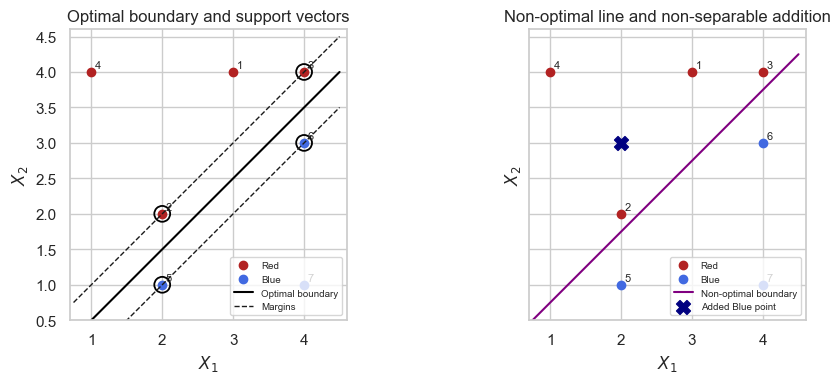

In [15]:
toy_points = pd.DataFrame({
    "X1": [3, 2, 4, 1, 2, 4, 4],
    "X2": [4, 2, 4, 4, 1, 3, 1],
    "Class": ["Red"] * 4 + ["Blue"] * 3,
    "Observation": range(1, 8),
})

figure, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
x_grid = np.linspace(0.75, 4.5, 200)

for axis in axes:
    for class_name, color in [("Red", "firebrick"), ("Blue", "royalblue")]:
        group = toy_points[toy_points["Class"] == class_name]
        axis.scatter(group["X1"], group["X2"], color=color, label=class_name)
    for row in toy_points.itertuples():
        axis.annotate(str(row.Observation), (row.X1 + 0.05, row.X2 + 0.05), fontsize=8)
    axis.set(xlabel="$X_1$", ylabel="$X_2$", xlim=(0.7, 4.6), ylim=(0.5, 4.6))
    axis.set_aspect("equal", adjustable="box")

axes[0].plot(x_grid, x_grid - 0.5, color="black", label="Optimal boundary")
axes[0].plot(x_grid, x_grid, "k--", linewidth=1, label="Margins")
axes[0].plot(x_grid, x_grid - 1, "k--", linewidth=1)
support_rows = toy_points[toy_points["Observation"].isin([2, 3, 5, 6])]
axes[0].scatter(
    support_rows["X1"], support_rows["X2"],
    s=130, facecolors="none", edgecolors="black", linewidths=1.3,
)
axes[0].set_title("Optimal boundary and support vectors")

axes[1].plot(
    x_grid, x_grid - 0.25, color="purple",
    label="Non-optimal boundary",
)
axes[1].scatter(
    [2], [3], marker="X", s=100, color="navy",
    label="Added Blue point",
)
axes[1].set_title("Non-optimal line and non-separable addition")

for axis in axes:
    axis.legend(fontsize=7, loc="lower right")

figure.tight_layout()
plt.show()


## References

- James, G., Witten, D., Hastie, T., and Tibshirani, R. *An Introduction to Statistical Learning with Applications in R*, corrected seventh printing.
- UCI Machine Learning Repository, APS Failure at Scania Trucks data description supplied with the assignment.
